<a href="https://colab.research.google.com/github/PioPio31/AnaliticaDeDatos_Equipo1/blob/main/Practica1_U4/Practica_1_Valdez_Escobedo_Montserrat.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Práctica Árbol de Decisión**
Montserrat Valdez Escobedo - 23111475

El dataset Student Study Habits & Stress, disponible en Kaggle, contiene 2,000 registros y 6 variables relacionadas con los hábitos de estudio, descanso, uso de redes sociales, rendimiento académico y niveles de estrés de estudiantes.

Este conjunto de datos permite analizar la relación entre los hábitos cotidianos y el estrés académico. Además, puede utilizarse para aplicar algoritmos de aprendizaje automático, como los árboles de decisión, con el objetivo de clasificar el nivel de estrés de los estudiantes en bajo, medio o alto a partir de sus características académicas y personales.


### Descripción de las variables del dataset
| Variable | Descripción | Tipo de dato | Función |
|---|---|---|---|
| **id** | Identificador único de cada estudiante. | Numérica | Identificador |
| **study_hours** | Cantidad de horas dedicadas al estudio. | Numérica | Independiente |
| **sleep_hours** | Cantidad de horas de sueño del estudiante. | Numérica | Independiente |
| **social_media_hours** | Tiempo dedicado al uso de redes sociales. | Numérica | Independiente |
| **exam_score** | Calificación obtenida en el examen. | Numérica | Independiente |
| **stress_level** | Nivel de estrés del estudiante (Low, Medium o High). | Categórica | Dependiente |

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv('/content/drive/MyDrive/Analitica_Datos_U3/Student_Stress_Dataset.csv')
data.head()

,id,study_hours,sleep_hours,social_media_hours,exam_score,stress_level
0,1,5.2,5.7,1.7,76,Medium
1,2,4.3,6.3,3.0,72,Medium
2,3,5.5,5.5,3.0,74,Medium
3,4,6.8,6.1,3.7,82,Medium
4,5,4.1,4.2,0.9,75,High


*Eliminamos la primera columna ya que solo el numero del registro*

In [ ]:
data.drop(data.columns[0], axis=1, inplace=True)

*Mostramos los primeros 5 datos del dataset y a partir de esta celda comenzamos a realizar el analisis exploratorio del mismo.*

In [ ]:
data.head()

,study_hours,sleep_hours,social_media_hours,exam_score,stress_level
0,5.2,5.7,1.7,76,Medium
1,4.3,6.3,3.0,72,Medium
2,5.5,5.5,3.0,74,Medium
3,6.8,6.1,3.7,82,Medium
4,4.1,4.2,0.9,75,High


In [ ]:
data.shape

(2000, 5)

In [ ]:
data.columns

Index(['study_hours', 'sleep_hours', 'social_media_hours', 'exam_score',
       'stress_level'],
      dtype='object')

In [ ]:
data.dtypes

,0
study_hours,float64
sleep_hours,float64
social_media_hours,float64
exam_score,int64
stress_level,object


In [ ]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
study_hours,2000.0,4.5683,1.478583,0.5,3.6,4.6,5.5,10.0
sleep_hours,2000.0,6.4908,1.202767,3.0,5.6,6.5,7.3,10.0
social_media_hours,2000.0,2.9439,1.460541,0.0,2.0,3.0,3.9,7.7
exam_score,2000.0,76.4170,10.114310,38.0,69.0,76.0,83.0,100.0


In [ ]:
data.describe(include = 'object').T

,count,unique,top,freq
stress_level,2000,3,Medium,1065


In [ ]:
data.isna().sum()

,0
study_hours,0
sleep_hours,0
social_media_hours,0
exam_score,0
stress_level,0


In [ ]:
data.duplicated().sum()

np.int64(0)

*Contamos el valor de cada una de las categorias de la variable predictora*

In [ ]:
data['stress_level'].value_counts()

,count
stress_level,
Medium,1065
Low,691
High,244


In [ ]:
data['stress_level'].value_counts(normalize=True)*100

,proportion
stress_level,
Medium,53.25
Low,34.55
High,12.20


**Codificacion de las graficas para analizar el comportamiento de los datos**

<Axes: xlabel='stress_level'>

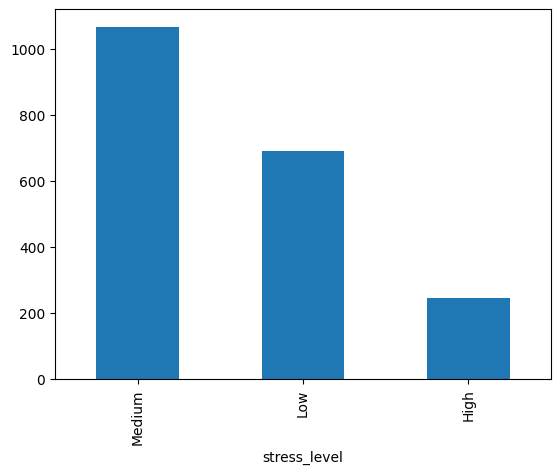

In [ ]:
data['stress_level'].value_counts().plot(kind='bar')

array([[<Axes: title={'center': 'study_hours'}>,
        <Axes: title={'center': 'sleep_hours'}>],
       [<Axes: title={'center': 'social_media_hours'}>,
        <Axes: title={'center': 'exam_score'}>]], dtype=object)

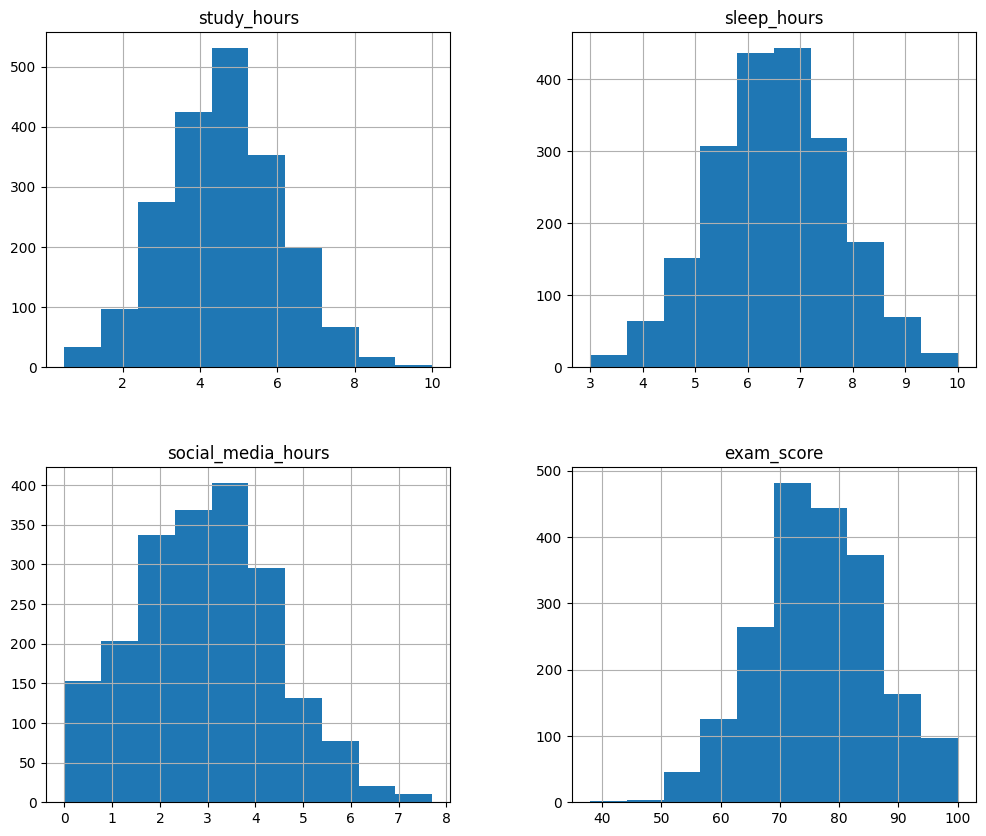

In [ ]:
data.hist(figsize=(12,10))

<Axes: >

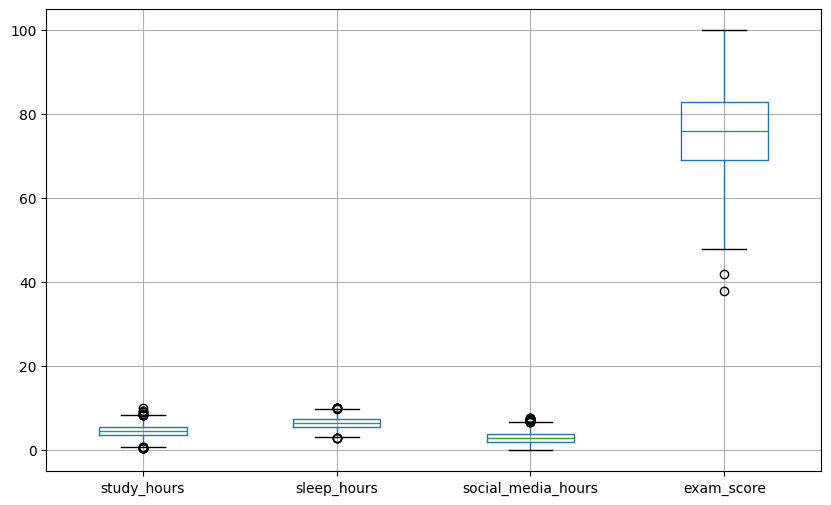

In [ ]:
data[['study_hours','sleep_hours','social_media_hours','exam_score']].boxplot(figsize=(10,6))

In [ ]:
q1 = data["study_hours"].quantile(0.25)
q3 = data["study_hours"].quantile(0.75)
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr
atipicos_horas = data[(data["study_hours"] < limite_inferior) |
                         (data["study_hours"] > limite_superior)]
print(f"Q1: {q1:.2f} | Q3: {q3:.2f} | IQR: {iqr:.2f}")
print(f"Límites: [{limite_inferior:.2f}, {limite_superior:.2f}]")
print(f"Registros atípicos en horas de estudio: {len(atipicos_horas)}")

Q1: 3.60 | Q3: 5.50 | IQR: 1.90
Límites: [0.75, 8.35]
Registros atípicos en horas de estudio: 24


In [ ]:
q1 = data["sleep_hours"].quantile(0.25)
q3 = data["sleep_hours"].quantile(0.75)
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr
atipicos_sleep = data[(data["sleep_hours"] < limite_inferior) |
                         (data["sleep_hours"] > limite_superior)]
print(f"Q1: {q1:.2f} | Q3: {q3:.2f} | IQR: {iqr:.2f}")
print(f"Límites: [{limite_inferior:.2f}, {limite_superior:.2f}]")
print(f"Registros atípicos en horas de sueño: {len(atipicos_sleep)}")

Q1: 5.60 | Q3: 7.30 | IQR: 1.70
Límites: [3.05, 9.85]
Registros atípicos en horas de sueño: 11


In [ ]:
q1 = data["social_media_hours"].quantile(0.25)
q3 = data["social_media_hours"].quantile(0.75)
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr
atipicos_social = data[(data["social_media_hours"] < limite_inferior) |
                         (data["social_media_hours"] > limite_superior)]
print(f"Q1: {q1:.2f} | Q3: {q3:.2f} | IQR: {iqr:.2f}")
print(f"Límites: [{limite_inferior:.2f}, {limite_superior:.2f}]")
print(f"Registros atípicos en horas en redes sociales: {len(atipicos_social)}")

Q1: 2.00 | Q3: 3.90 | IQR: 1.90
Límites: [-0.85, 6.75]
Registros atípicos en horas en redes sociales: 15


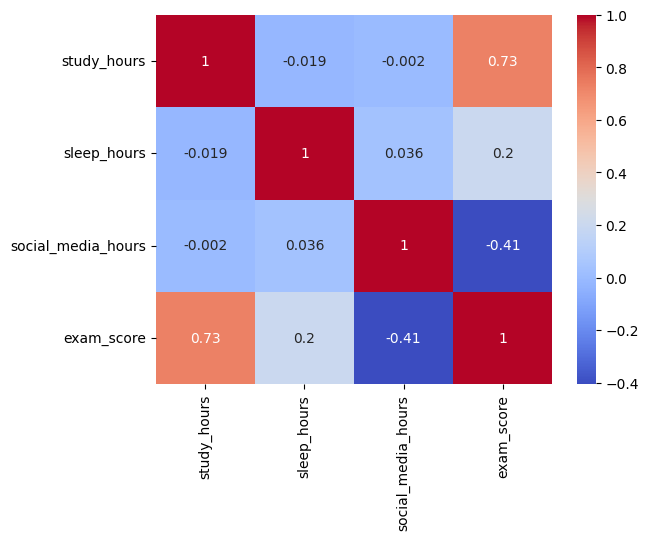

In [ ]:
sns.heatmap(data[['study_hours','sleep_hours','social_media_hours','exam_score']].corr(),annot=True,cmap='coolwarm')
plt.show()

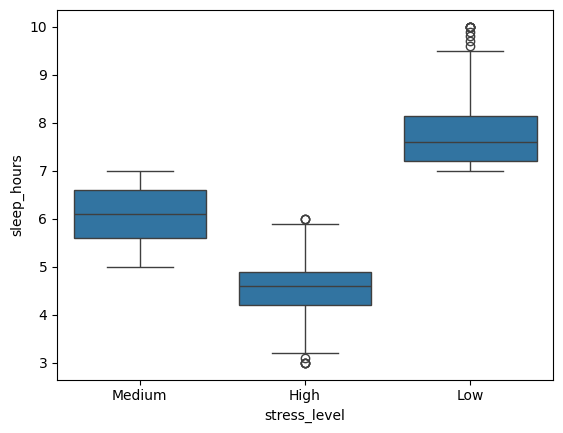

In [ ]:
sns.boxplot(data=data, x='stress_level', y='sleep_hours')
plt.show()

**Inicio del modelo de machine learning**

---



In [ ]:
#Importacion de librerias
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn import metrics

In [ ]:
#Variables independientes
X=data.drop('stress_level',axis=1)
#Variable predictora
y=data['stress_level']

In [ ]:
#Dividimos el conjunto de prueba y entrenamiento
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=1)

In [ ]:
#Creamos el objeto del arbol de decision
clf = DecisionTreeClassifier()
#Entrenamiento del arbol con fit()
clf = clf.fit(X_train, y_train)
#Generamos predicciones a partir de los datos de prueba
y_pred = clf.predict(X_test)

In [ ]:
#Imprimimos el Accuracy para ver que tan correcto clasifico
from sklearn.metrics import classification_report

print ("Accuracy: ", metrics.accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy:  0.965
              precision    recall  f1-score   support

        High       1.00      0.89      0.94        53
         Low       0.98      0.95      0.97       132
      Medium       0.95      0.99      0.97       215

    accuracy                           0.96       400
   macro avg       0.98      0.94      0.96       400
weighted avg       0.97      0.96      0.96       400



Matriz de confusion

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

matriz = confusion_matrix(y_test, y_pred)
print("Matriz de confusión:")
print(matriz)

Matriz de confusión:
[[ 47   0   6]
 [  0 126   6]
 [  0   2 213]]


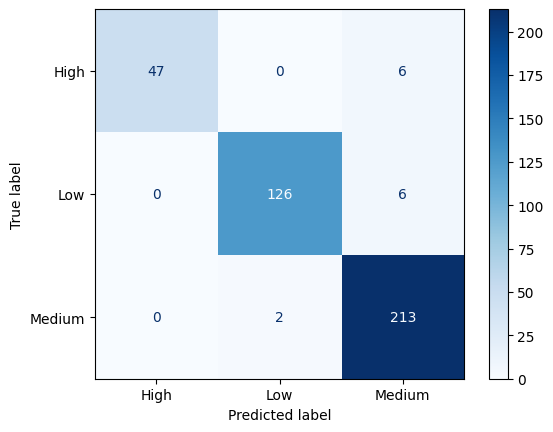

In [ ]:
ConfusionMatrixDisplay.from_estimator(clf, X_test, y_test, cmap='Blues')

plt.show()

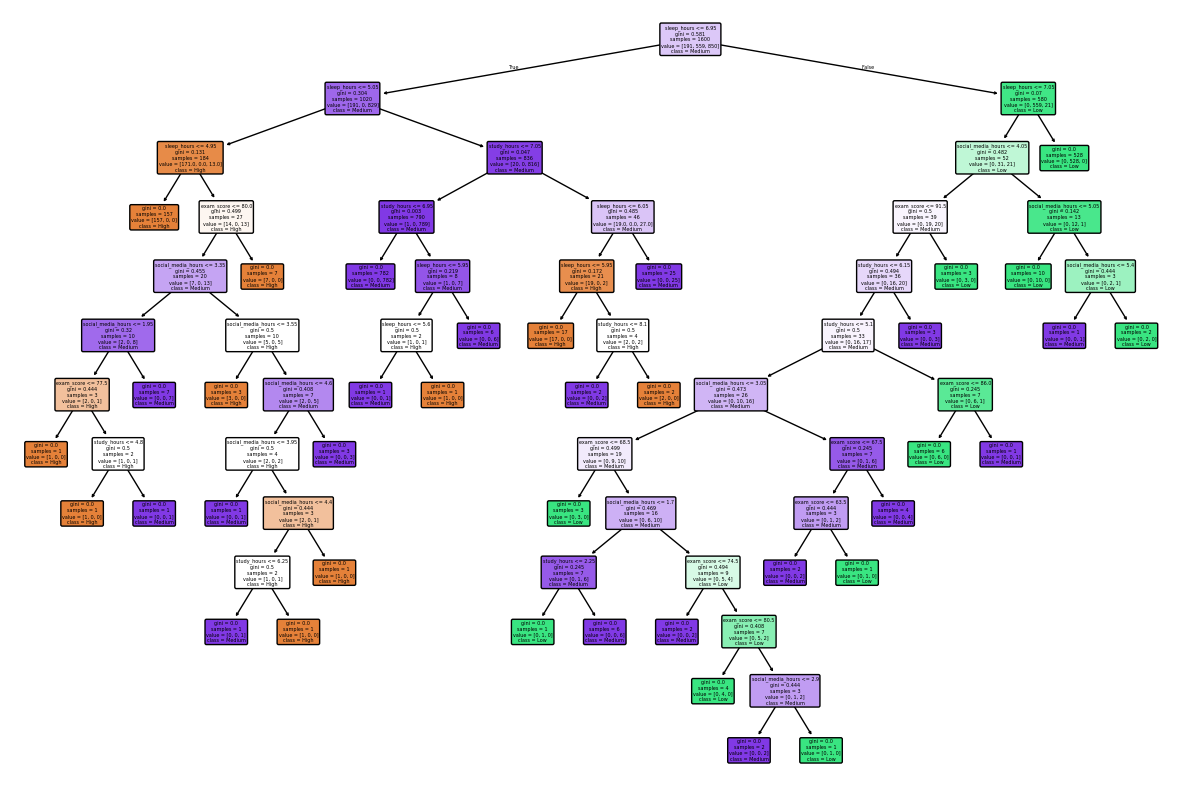

In [ ]:
from sklearn.tree import plot_tree

plt.figure(figsize=(15, 10))
plot_tree(clf, feature_names=X.columns, class_names=clf.classes_, filled=True, rounded=True)
plt.show()

**Conclusión**

En esta práctica se implementó un modelo de árbol de decisión para clasificar el nivel de estrés de los estudiantes a partir de sus hábitos de estudio, horas de sueño, tiempo en redes sociales y calificaciones. Primero se realizó un análisis exploratorio de los datos, donde se identificó que la mayoría de los estudiantes presentaban un nivel de estrés medio y que existían relaciones importantes entre algunas variables.
Algo que se puede observar en este analisis es la relacion entre las horas de sueño y el nivel de estres, ya que los estudiantes con altos niveles de estres generalmente duermen menos, mientras que aquellos con niveles bajos descansan mas.
Posteriormente se entreno y evaluo el árbol de decisión generado donde se obtuvo un accuracy del 96.5%, logrando clasificar correctamente 386 de los 400 registros de prueba. Aunque el modelo presento algunos errores, sobretodo al identificar estudiantes con estres alto, los resultados fueron favorables de manera general.
En general esta practica abrio la puerta para poder reforzar los conocimientos adquiridos en la unidad anterior y comprender como funciona un árbol de decisión, sobre todo su uso para clasificar datos utilizando diferentes caracteristicas.


**Referencias Bibliograficas**

Student Study Habits Stress Dataset. (26 de Abril del 2026). https://www.kaggle.com/datasets/sureshbeekhani/student-study-habits-stress-dataset/#1